# Model Results Analysis

This notebook reads `runs/results.json` produced by `python -m src.baselines` and analyzes the baseline models **with and without PCA**.

The analysis covers:

1. Aggregate metrics for all clothing classes.
2. Per-class precision, recall, and F1 for each clothing category.
3. The effect of PCA on accuracy, macro-F1, and training time.
4. Normalized confusion matrices and the most frequent misclassifications.
5. Data-driven conclusions for model selection.

## 1. Load the results


In [55]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

CURRENT_DIR = Path.cwd()
candidates = [CURRENT_DIR, CURRENT_DIR.parent, CURRENT_DIR / "Workshop_1"]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "runs" / "results.json").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate runs/results.json. Run this notebook from the project root or notebooks/."
    )

RESULTS_PATH = PROJECT_ROOT / "runs" / "results.json"
results = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))

VARIANTS = list(results["experiments"])
MODELS = list(dict.fromkeys(
    model
    for experiment in results["experiments"].values()
    for model in experiment["models"]
))

# Class order follows the classifier's label order (0-9)
first_experiment = next(iter(results["experiments"].values()))
first_model = next(iter(first_experiment["models"].values()))
CLASS_NAMES = list(first_model["test"]["per_class"].keys())

VARIANT_LABELS = {"no_aug_no_pca": "No augmentation No PCA", "no_aug_pca": "No augmentation with PCA",
                  "aug_no_pca": "With augmentation No PCA", "aug_pca" : "With augmentation with PCA"}
VARIANT_COLORS = {"no_aug_no_pca": "#2b5c8f", "no_aug_pca": "#0788af",
                  "aug_no_pca": "#d30700", "aug_pca": "#d35400"}
MODEL_ORDER = MODELS

print(f"Results file: {RESULTS_PATH}")
print(f"Feature variants: {VARIANTS}")
print(f"Models: {MODELS}")
print(f"Classes ({len(CLASS_NAMES)}): {CLASS_NAMES}")

Results file: /home/juanandresjp/Documentos/UD/Semestre10/MachineLearning/Workshop_1/runs/results.json
Feature variants: ['no_aug_no_pca', 'no_aug_pca', 'aug_no_pca', 'aug_pca']
Models: ['Logistic_Regression', 'Random_Forest', 'Hist_Gradient_Boosting']
Classes (10): ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## 2. Aggregate metrics

The aggregate metrics evaluate all clothing classes together. Macro averages weight every class equally, which is appropriate here because Fashion-MNIST is balanced; weighted averages also account for class support.

In [56]:
metric_rows = []
for variant, experiment in results["experiments"].items():
    for model_name, model_data in experiment["models"].items():
        for split in ("validation", "test"):
            metrics = model_data[split]
            metric_rows.append({
                "Variant": variant,
                "Variant label": VARIANT_LABELS.get(variant, variant),
                "Model": model_name,
                "Split": split,
                "Accuracy": metrics["accuracy"],
                "Precision macro": metrics["precision_macro"],
                "Recall macro": metrics["recall_macro"],
                "F1 macro": metrics["f1_macro"],
                "Precision weighted": metrics["precision_weighted"],
                "Recall weighted": metrics["recall_weighted"],
                "F1 weighted": metrics["f1_weighted"],
                "ROC-AUC macro": metrics["roc_auc_ovr_macro"],
                "Train time (s)": model_data["train_time_sec"],
            })

metrics_df = pd.DataFrame(metric_rows)
test_metrics = metrics_df[metrics_df["Split"] == "test"].copy()
test_metrics["Model"] = pd.Categorical(test_metrics["Model"], categories=MODEL_ORDER, ordered=True)
test_metrics["Variant"] = pd.Categorical(test_metrics["Variant"], categories=VARIANTS, ordered=True)
test_metrics = test_metrics.sort_values(["Model", "Variant"]).reset_index(drop=True)

summary_columns = [
    "Model", "Variant label", "Accuracy", "Precision macro", "Recall macro",
    "F1 macro", "ROC-AUC macro", "Train time (s)",
]
with pd.option_context("display.float_format", "{:.4f}".format):
    display(test_metrics[summary_columns])

,Model,Variant label,Accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC macro,Train time (s)
0,Logistic_Regression,No augmentation No PCA,0.8403,0.8382,0.8403,0.8389,0.9815,182.1143
1,Logistic_Regression,No augmentation with PCA,0.8529,0.8513,0.8529,0.8516,0.9836,9.9546
2,Logistic_Regression,With augmentation No PCA,0.8299,0.8281,0.8299,0.8283,0.9807,152.1686
3,Logistic_Regression,With augmentation with PCA,0.8412,0.8389,0.8412,0.8394,0.9821,10.4696
4,Random_Forest,No augmentation No PCA,0.8815,0.8805,0.8815,0.8799,0.9901,10.2270
5,Random_Forest,No augmentation with PCA,0.8590,0.8575,0.8590,0.8565,0.9866,16.0280
6,Random_Forest,With augmentation No PCA,0.8794,0.8785,0.8794,0.8774,0.9896,12.6561
7,Random_Forest,With augmentation with PCA,0.8570,0.8559,0.8570,0.8543,0.9869,17.7671
8,Hist_Gradient_Boosting,No augmentation No PCA,0.9011,0.9009,0.9011,0.9008,0.9929,96.0865
9,Hist_Gradient_Boosting,No augmentation with PCA,0.8748,0.8739,0.8748,0.8740,0.9899,43.1046


## 3. Overall comparison by model and PCA setting

In [66]:
def plot_model_comparison(
    variants,
    comparison_title,
    columns=2,
    metrics=None,
):
    if metrics is None:
        metrics = ["Accuracy", "F1 macro"]

    lookup = test_metrics.set_index(["Model", "Variant"])

    n_plots = len(metrics)
    rows = int(np.ceil(n_plots / columns))

    x = np.arange(len(MODEL_ORDER))
    width = 0.8 / len(variants)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(6 * columns, 5 * rows),
        squeeze=False,
    )

    axes = axes.flatten()

    offsets = (
        np.arange(len(variants)) - (len(variants) - 1) / 2
    ) * width

    for ax, metric in zip(axes, metrics):

        for offset, variant in zip(offsets, variants):

            values = [
                lookup.loc[(model, variant), metric]
                for model in MODEL_ORDER
            ]

            bars = ax.bar(
                x + offset,
                values,
                width,
                label=VARIANT_LABELS.get(variant, variant),
                color=VARIANT_COLORS.get(variant, None),
                edgecolor="black",
                linewidth=0.6,
            )

            ax.bar_label(
                bars,
                fmt="%.3f",
                padding=2,
                fontsize=8,
            )

        ax.set_title(metric, fontsize=12, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(MODEL_ORDER, rotation=15, ha="right")
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1.05)
        ax.legend(frameon=False, fontsize=8)

    # Remove unused subplots
    for ax in axes[n_plots:]:
        fig.delaxes(ax)

    fig.suptitle(
        comparison_title,
        fontsize=14,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

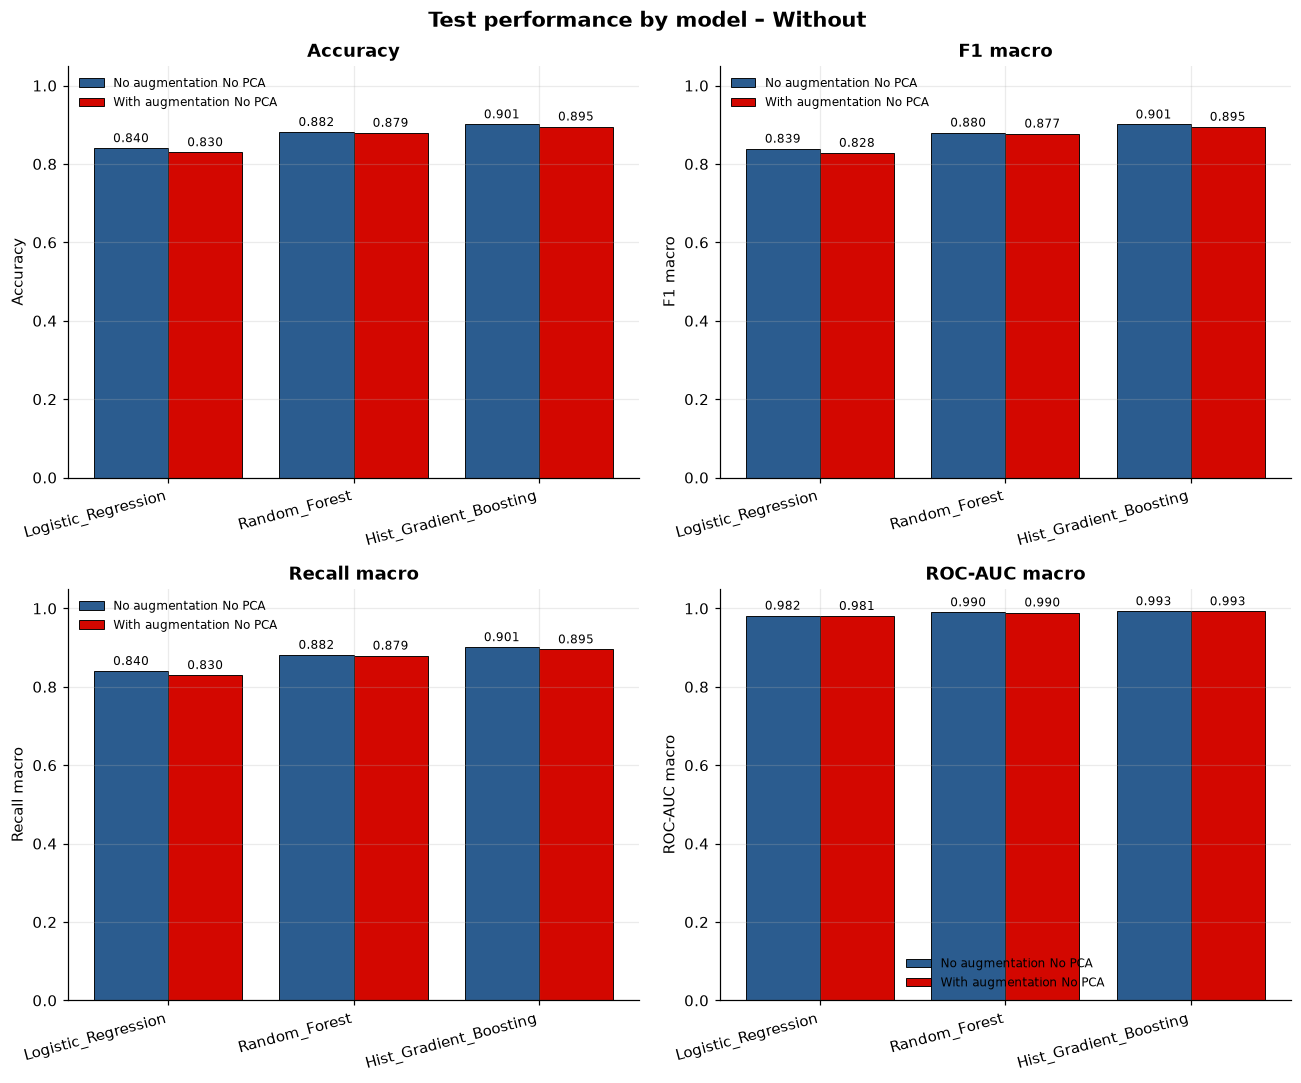

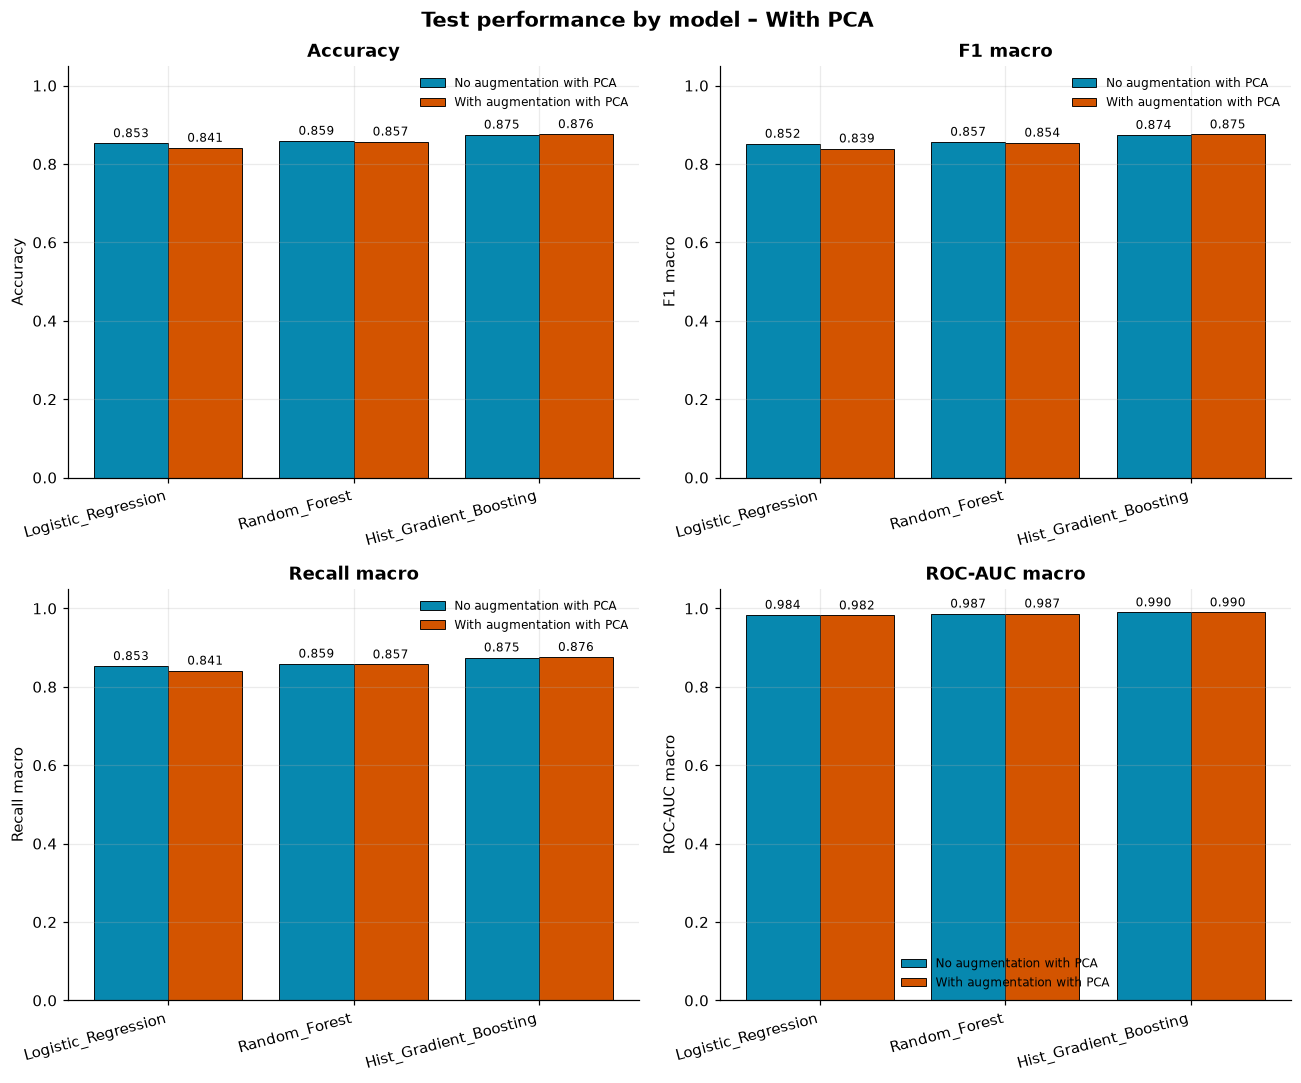

In [67]:
# Experiment 1: Without PCA
plot_model_comparison(
    variants=["no_aug_no_pca", "aug_no_pca"],
    comparison_title="Test performance by model – Without",
    columns=2,
    metrics=["Accuracy", "F1 macro", "Recall macro", "ROC-AUC macro"]
)

# Experiment 2: With PCA
plot_model_comparison(
    variants=["no_aug_pca", "aug_pca"],
    comparison_title="Test performance by model – With PCA",
    columns=2,
    metrics=["Accuracy", "F1 macro", "Recall macro", "ROC-AUC macro"]
)

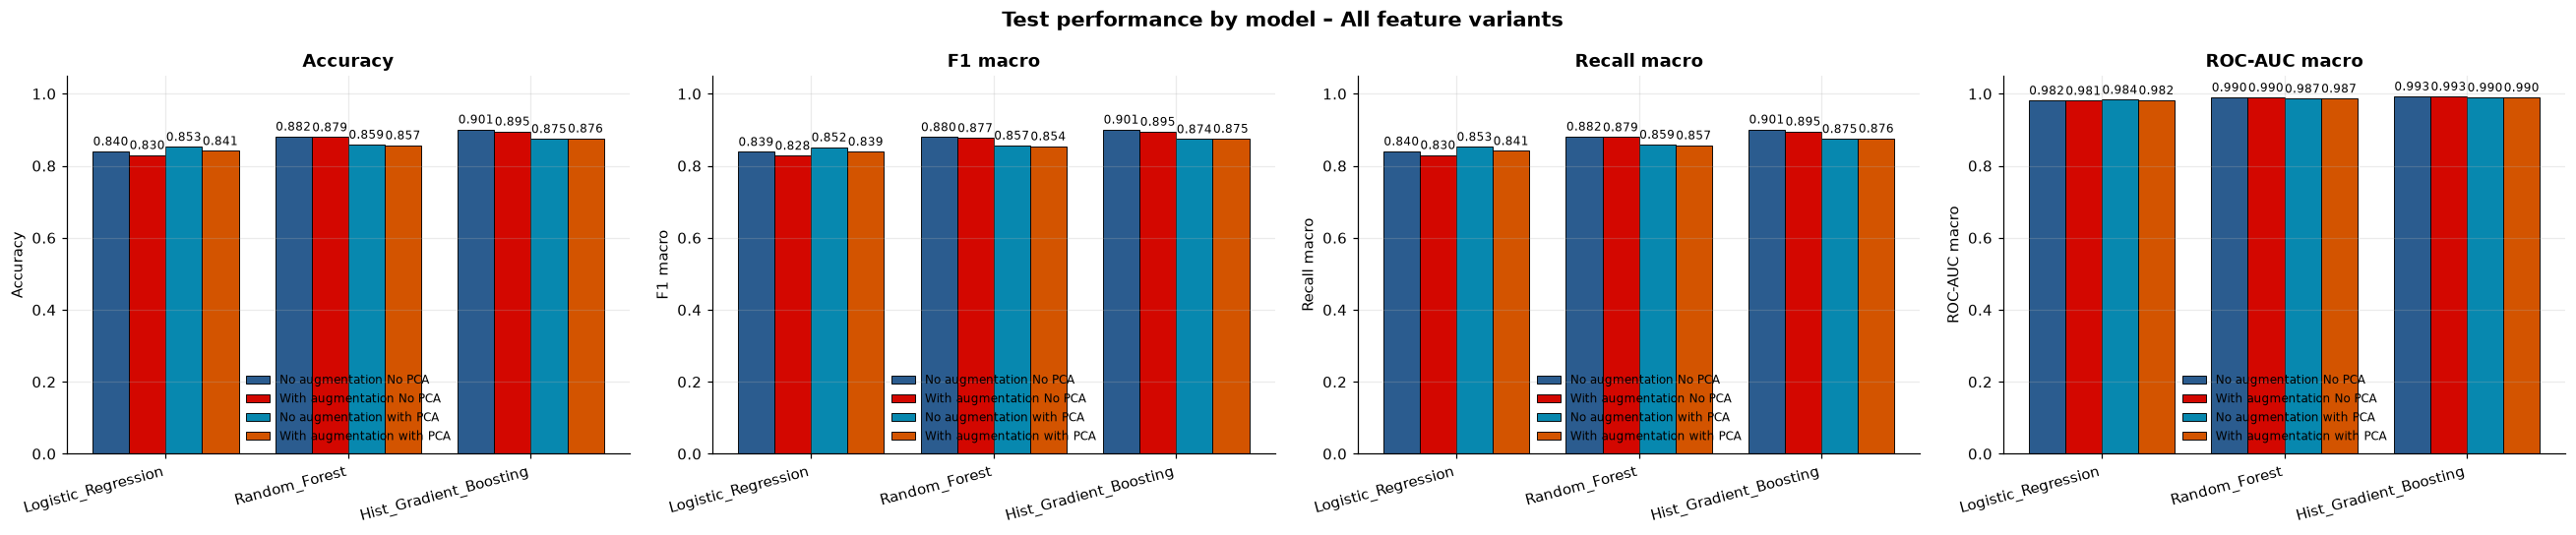

In [68]:
plot_model_comparison(
    variants=["no_aug_no_pca", "aug_no_pca", "no_aug_pca", "aug_pca"],
    comparison_title="Test performance by model – All feature variants",
    columns=4,
    metrics=["Accuracy", "F1 macro", "Recall macro", "ROC-AUC macro"],
)

### Accuracy versus training time

This shows whether a model's extra training cost translates into better test performance.

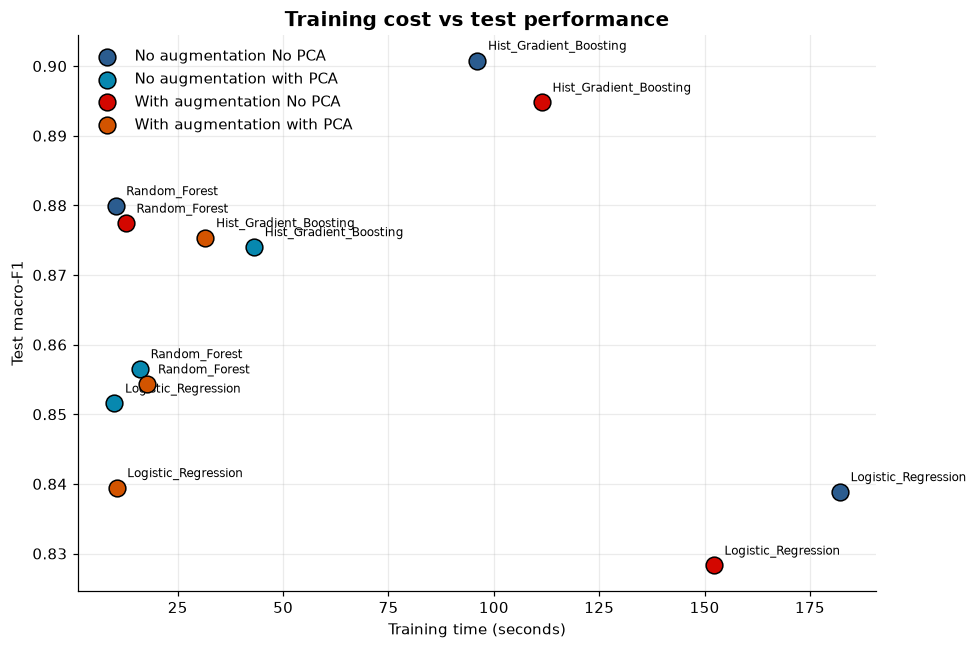

In [69]:
fig, ax = plt.subplots(figsize=(9, 6))
for variant in VARIANTS:
    subset = test_metrics[test_metrics["Variant"] == variant]
    ax.scatter(
        subset["Train time (s)"],
        subset["F1 macro"],
        s=120,
        label=VARIANT_LABELS.get(variant, variant),
        color=VARIANT_COLORS.get(variant, None),
        edgecolor="black",
        zorder=3,
    )
    for _, row in subset.iterrows():
        ax.annotate(
            row["Model"],
            (row["Train time (s)"], row["F1 macro"]),
            textcoords="offset points",
            xytext=(7, 7),
            fontsize=8,
        )

ax.set_xlabel("Training time (seconds)")
ax.set_ylabel("Test macro-F1")
ax.set_title("Training cost vs test performance", fontsize=13, fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. Per-class analysis

Fashion-MNIST is a 10-class problem, so aggregate accuracy can hide weak categories. The next cells break performance down by clothing class.

In [70]:
per_class_rows = []
for variant, experiment in results["experiments"].items():
    for model_name, model_data in experiment["models"].items():
        for split in ("validation", "test"):
            for class_name, values in model_data[split]["per_class"].items():
                per_class_rows.append({
                    "Variant": variant,
                    "Variant label": VARIANT_LABELS.get(variant, variant),
                    "Model": model_name,
                    "Split": split,
                    "Class": class_name,
                    "Precision": values["precision"],
                    "Recall": values["recall"],
                    "F1": values["f1_score"],
                    "Support": values["support"],
                })

per_class_df = pd.DataFrame(per_class_rows)
test_per_class = per_class_df[per_class_df["Split"] == "test"].copy()

with pd.option_context("display.float_format", "{:.4f}".format):
    display(
        test_per_class[["Model", "Variant label", "Class", "Precision", "Recall", "F1"]]
        .sort_values(["Model", "Variant label", "Class"])
        .head(20)
    )

,Model,Variant label,Class,Precision,Recall,F1
59,Hist_Gradient_Boosting,No augmentation No PCA,Ankle boot,0.9702,0.9619,0.9660
58,Hist_Gradient_Boosting,No augmentation No PCA,Bag,0.9780,0.9752,0.9766
54,Hist_Gradient_Boosting,No augmentation No PCA,Coat,0.8011,0.8514,0.8255
53,Hist_Gradient_Boosting,No augmentation No PCA,Dress,0.9047,0.9219,0.9132
52,Hist_Gradient_Boosting,No augmentation No PCA,Pullover,0.8346,0.8267,0.8306
55,Hist_Gradient_Boosting,No augmentation No PCA,Sandal,0.9856,0.9781,0.9818
56,Hist_Gradient_Boosting,No augmentation No PCA,Shirt,0.7402,0.6867,0.7125
57,Hist_Gradient_Boosting,No augmentation No PCA,Sneaker,0.9549,0.9676,0.9612
50,Hist_Gradient_Boosting,No augmentation No PCA,T-shirt/top,0.8462,0.8648,0.8554
51,Hist_Gradient_Boosting,No augmentation No PCA,Trouser,0.9932,0.9771,0.9851


### Per-class F1 heatmap

Each row is a clothing category; each column is a model/feature representation. Darker or lighter colors quickly show which classes are consistently difficult.

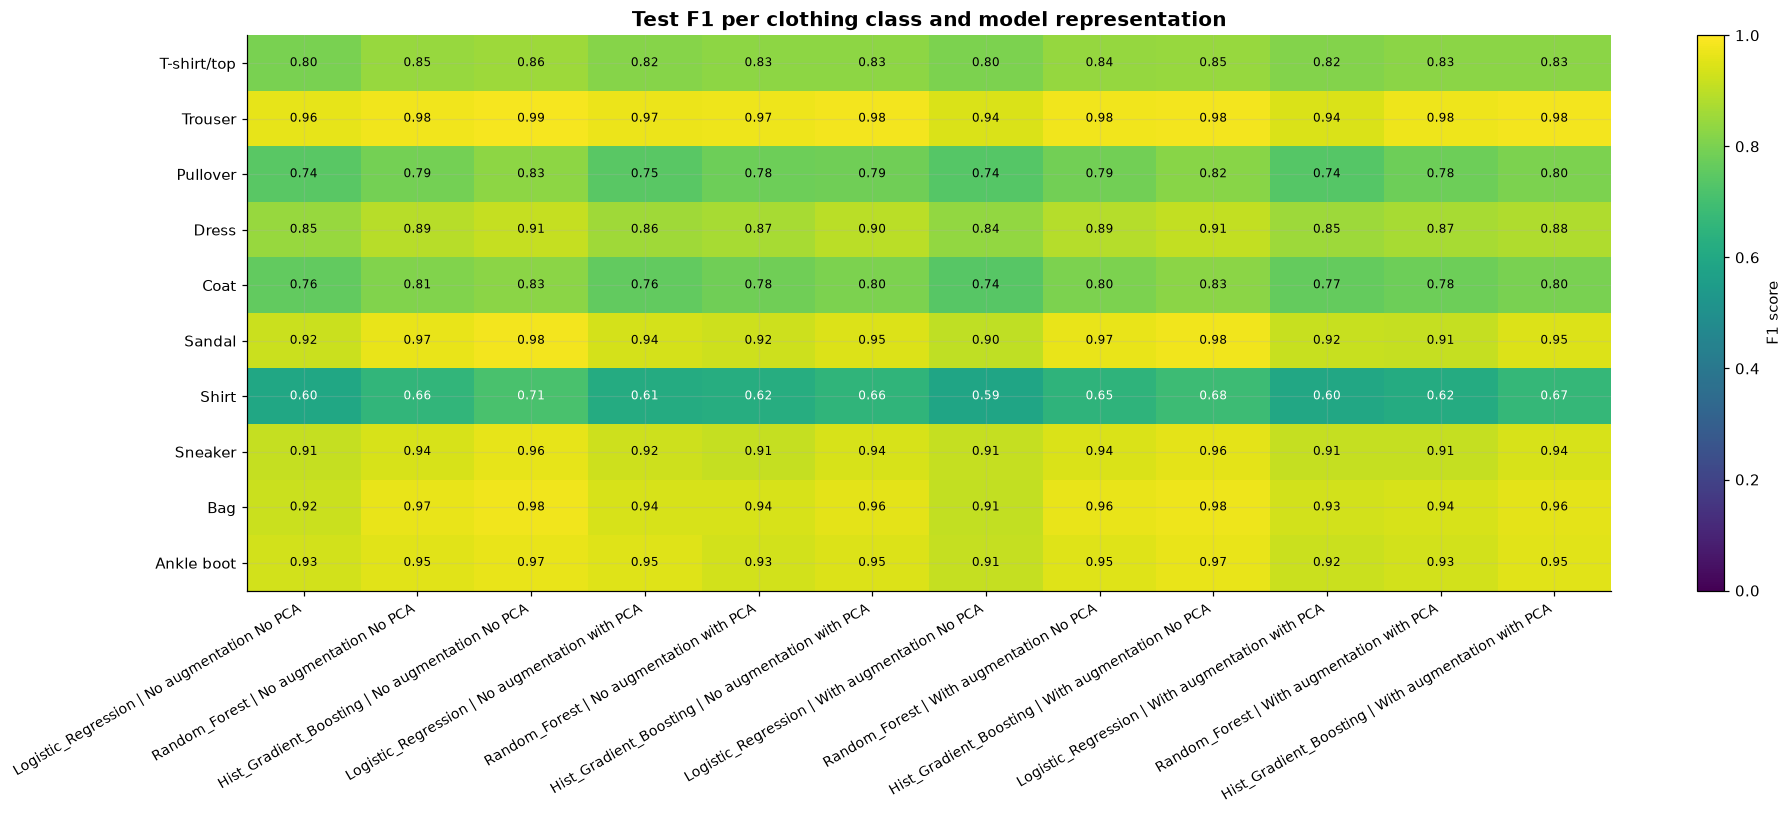

In [71]:
test_per_class["Model variant"] = test_per_class["Model"] + " | " + test_per_class["Variant label"]
column_order = [
    f"{model} | {VARIANT_LABELS.get(variant, variant)}"
    for variant in VARIANTS
    for model in MODEL_ORDER
]

f1_matrix = (
    test_per_class
    .pivot(index="Class", columns="Model variant", values="F1")
    .reindex(index=CLASS_NAMES, columns=column_order)
)

fig, ax = plt.subplots(figsize=(max(10, len(column_order) * 1.5), 7.5))
image = ax.imshow(f1_matrix.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(column_order)))
ax.set_xticklabels(column_order, rotation=30, ha="right", fontsize=9)
ax.set_yticks(np.arange(len(CLASS_NAMES)))
ax.set_yticklabels(CLASS_NAMES)
ax.set_title("Test F1 per clothing class and model representation", fontsize=13, fontweight="bold")

for row in range(f1_matrix.shape[0]):
    for col in range(f1_matrix.shape[1]):
        value = f1_matrix.iloc[row, col]
        color = "white" if value < 0.72 else "black"
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color=color)

fig.colorbar(image, ax=ax, label="F1 score")
plt.tight_layout()
plt.show()

### Best model: precision, recall, and F1 per class

The best model/variant pair is selected by test macro-F1, then its per-class behavior is shown.

Best model by test macro-F1: Hist_Gradient_Boosting (No augmentation No PCA), F1=0.9008, accuracy=0.9011


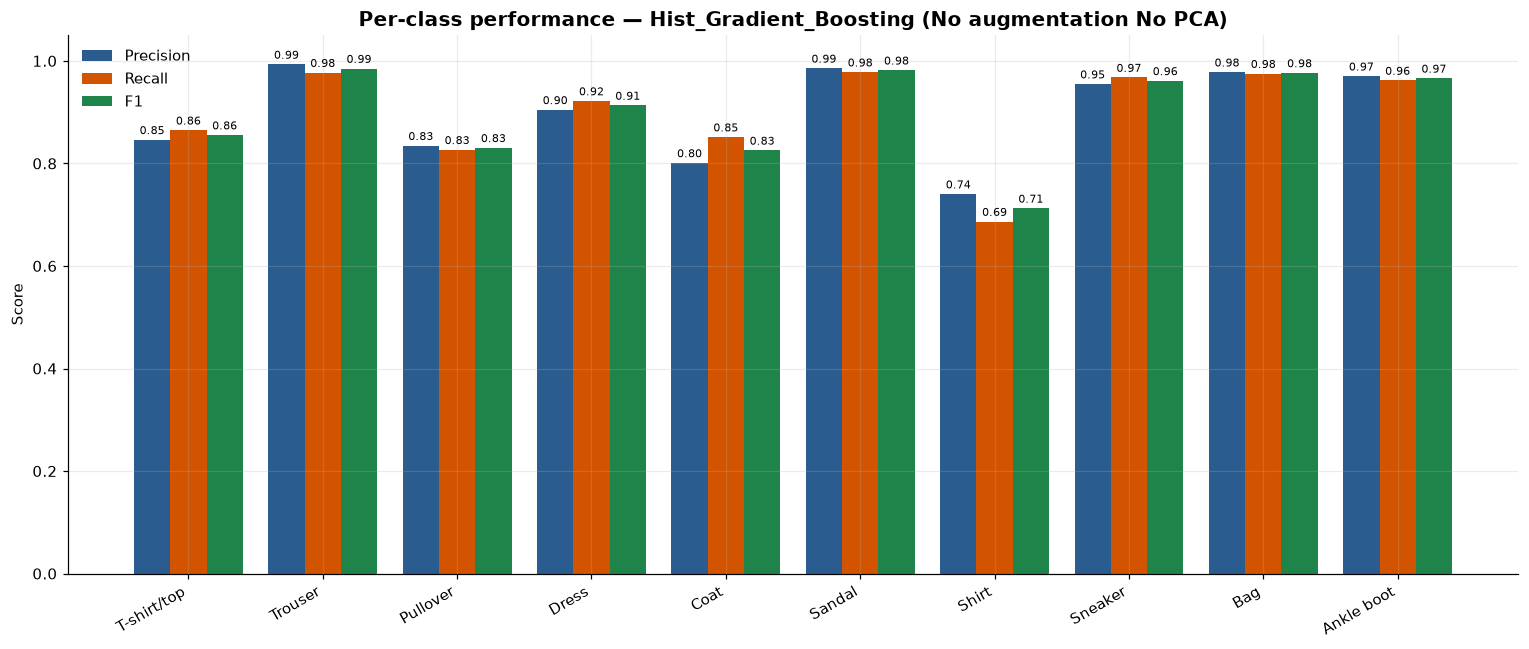

In [72]:
best_row = test_metrics.sort_values("F1 macro", ascending=False).iloc[0]
best_model = best_row["Model"]
best_variant = best_row["Variant"]
best_per_class = (
    test_per_class[
        (test_per_class["Model"] == best_model)
        & (test_per_class["Variant"] == best_variant)
    ]
    .set_index("Class")
    .reindex(CLASS_NAMES)
)

print(
    f"Best model by test macro-F1: {best_model} "
    f"({VARIANT_LABELS.get(best_variant, best_variant)}), "
    f"F1={best_row['F1 macro']:.4f}, accuracy={best_row['Accuracy']:.4f}"
)

x = np.arange(len(CLASS_NAMES))
width = 0.27
fig, ax = plt.subplots(figsize=(14, 6))
for offset, metric, color in zip(
    (-width, 0, width),
    ["Precision", "Recall", "F1"],
    ["#2b5c8f", "#d35400", "#1e8449"],
):
    bars = ax.bar(x + offset, best_per_class[metric], width, label=metric, color=color)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(
    f"Per-class performance — {best_model} ({VARIANT_LABELS.get(best_variant, best_variant)})",
    fontsize=13,
    fontweight="bold",
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Confusion matrices

The matrices are normalized by true class: each row sums to 1.0. Diagonal cells are correct predictions; off-diagonal cells show which clothing categories are confused.

In [82]:

def plot_confusion_matrices(
    models,
    variants,
    comparison_title="Normalized test confusion matrices",
    figsize=None,
    cmap="Blues",
    threshold=0.01,
):
    n_rows = len(models)
    n_cols = len(variants)

    if figsize is None:
        figsize = (5 * n_cols, 4 * n_rows)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=figsize,
        squeeze=False,
        constrained_layout=True,
    )

    for row, model in enumerate(models):
        for col, variant in enumerate(variants):

            ax = axes[row, col]

            cm = np.asarray(
                results["experiments"][variant]
                ["models"][model]["test"]["confusion_matrix"]
            )

            # Normalize by true class
            row_sums = cm.sum(axis=1, keepdims=True)
            cm_normalized = np.divide(
                cm,
                row_sums,
                out=np.zeros_like(cm, dtype=float),
                where=row_sums != 0,
            )

            image = ax.imshow(
                cm_normalized,
                cmap=cmap,
                vmin=0,
                vmax=1,
            )

            ax.set_title(
                f"{model}\n{VARIANT_LABELS.get(variant, variant)}",
                fontsize=10,
                fontweight="bold",
            )

            ax.set_xticks(np.arange(len(CLASS_NAMES)))
            ax.set_yticks(np.arange(len(CLASS_NAMES)))

            ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
            ax.set_yticklabels(CLASS_NAMES, fontsize=7)

            ax.set_xlabel("Predicted class", fontsize=8)
            ax.set_ylabel("True class", fontsize=8)

            ax.grid(False)

            # Annotate relevant values
            for i in range(len(CLASS_NAMES)):
                for j in range(len(CLASS_NAMES)):

                    value = cm_normalized[i, j]

                    if value >= threshold:
                        ax.text(
                            j,
                            i,
                            f"{value:.2f}",
                            ha="center",
                            va="center",
                            fontsize=5.5,
                            color="white" if value > 0.55 else "black",
                        )

    # Shared colorbar
    fig.colorbar(
        image,
        ax=axes.ravel().tolist(),
        label="Proportion of true class",
        shrink=0.8,
        pad=0.02,
    )

    fig.suptitle(
        comparison_title,
        fontsize=15,
        fontweight="bold",
        y=1.04,
    )

    plt.show()


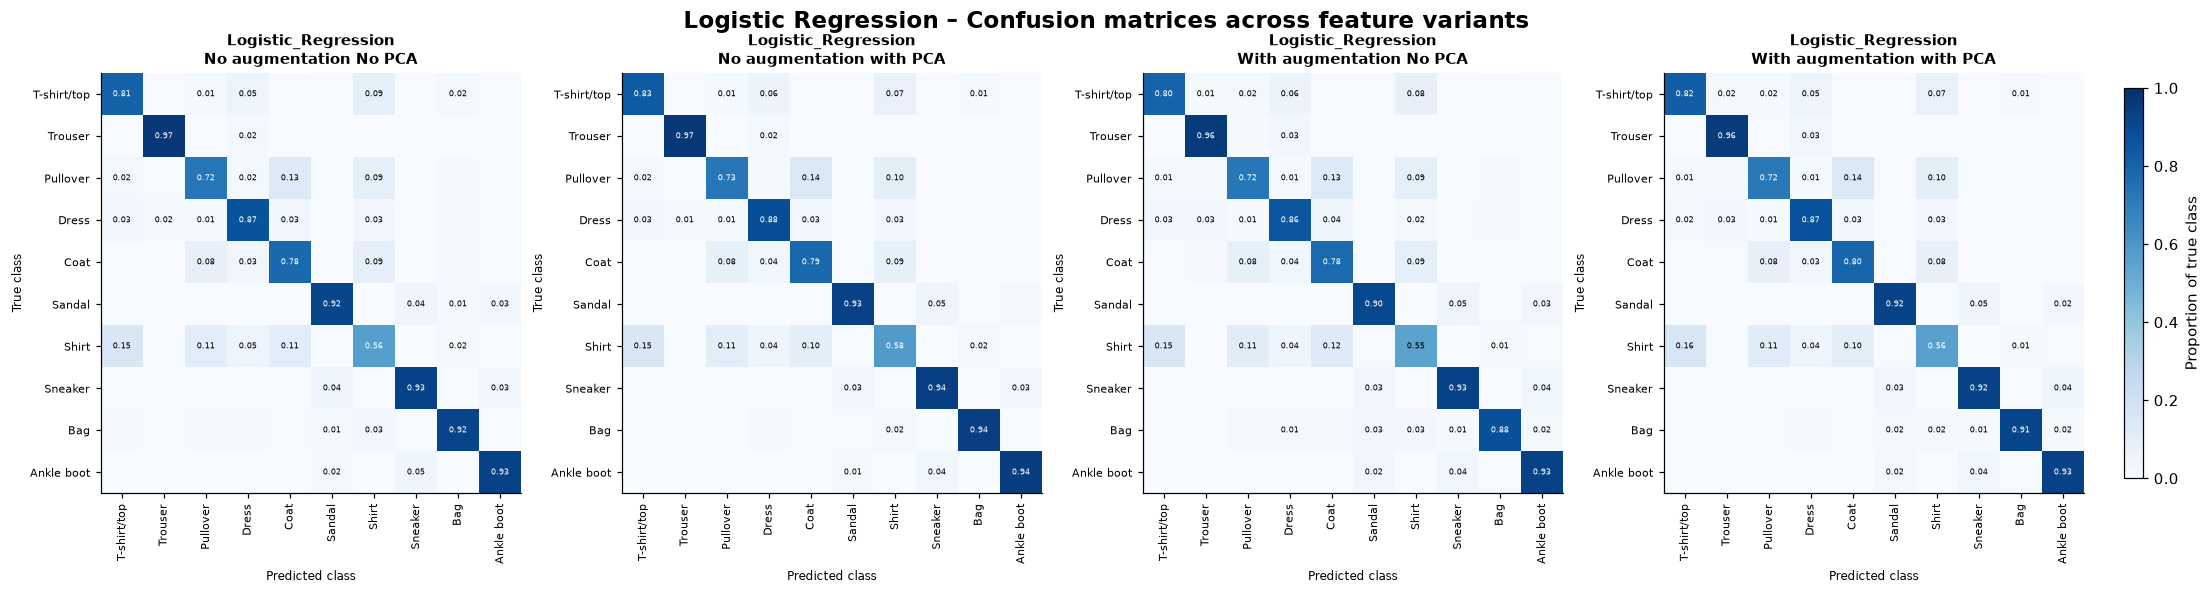

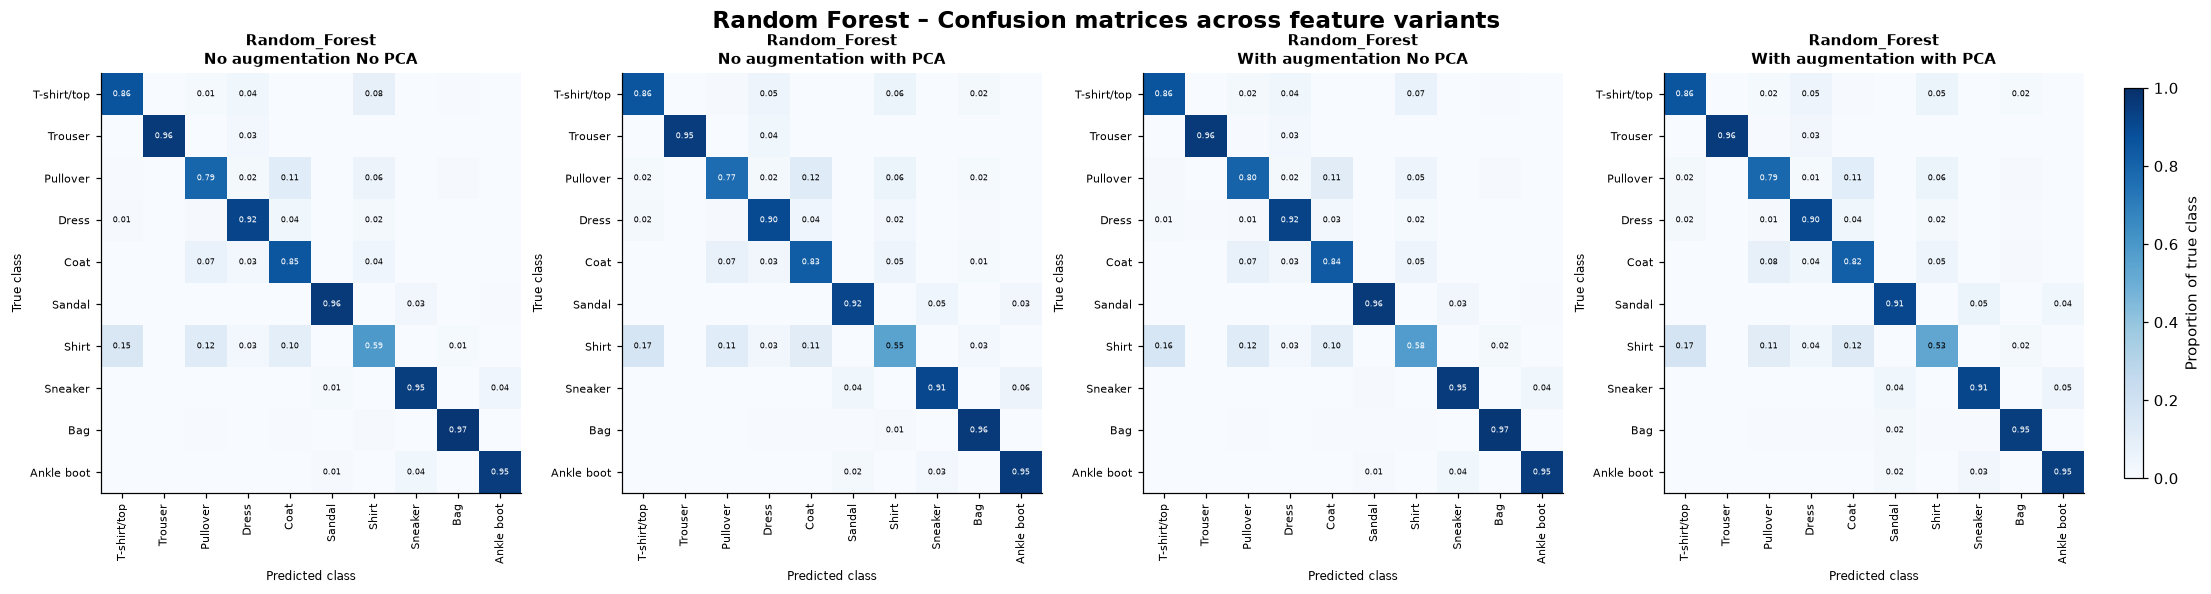

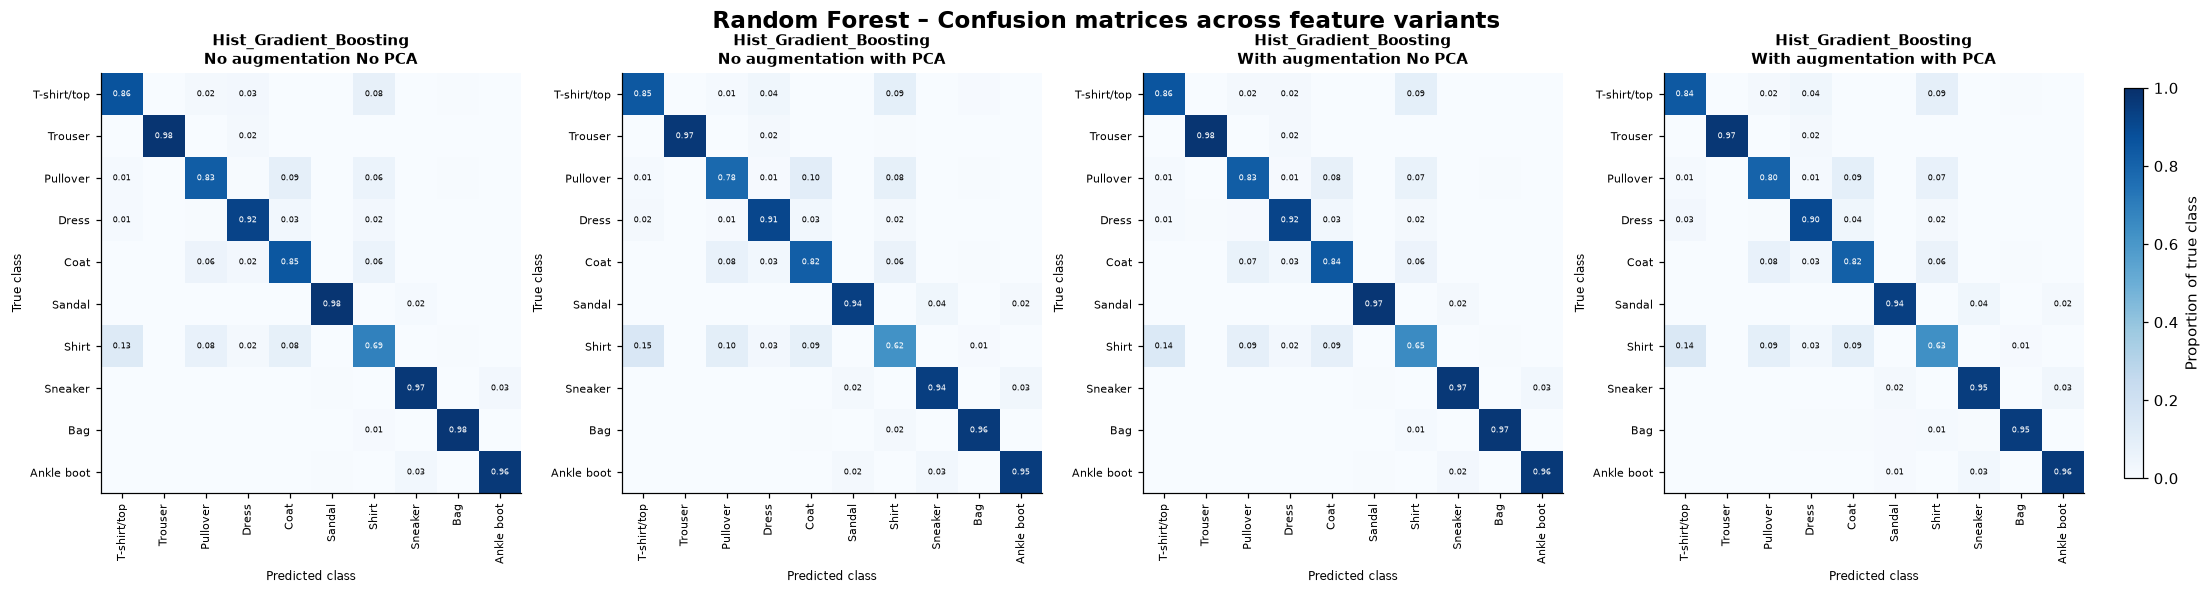

In [83]:
#Confusion Matrix per model

plot_confusion_matrices(
    models=["Logistic_Regression"],
    variants=VARIANTS,
    comparison_title="Logistic Regression – Confusion matrices across feature variants",
    figsize=(20, 5),
)

plot_confusion_matrices(
    models=["Random_Forest"],
    variants=VARIANTS,
    comparison_title="Random Forest – Confusion matrices across feature variants",
    figsize=(20, 5),
)

plot_confusion_matrices(
    models=["Hist_Gradient_Boosting"],
    variants=VARIANTS,
    comparison_title="Random Forest – Confusion matrices across feature variants",
    figsize=(20, 5),
)




### Most frequent misclassifications

This table lists the largest off-diagonal confusion-matrix cells. It makes the main error patterns explicit.

In [84]:
confusion_rows = []
for variant, experiment in results["experiments"].items():
    for model_name, model_data in experiment["models"].items():
        cm = np.asarray(model_data["test"]["confusion_matrix"], dtype=float)
        cm_copy = cm.copy()
        np.fill_diagonal(cm_copy, 0)
        for index in np.argsort(cm_copy.ravel())[::-1][:3]:
            true_idx, predicted_idx = np.unravel_index(index, cm_copy.shape)
            confusion_rows.append({
                "Variant": variant,
                "Variant label": VARIANT_LABELS.get(variant, variant),
                "Model": model_name,
                "True class": CLASS_NAMES[true_idx],
                "Predicted as": CLASS_NAMES[predicted_idx],
                "Count": int(cm[true_idx, predicted_idx]),
                "Share of true class": cm[true_idx, predicted_idx] / cm[true_idx].sum(),
            })

top_confusions = pd.DataFrame(confusion_rows)
with pd.option_context("display.float_format", "{:.2%}".format):
    display(
        top_confusions.sort_values(
            ["Variant", "Model", "Count"], ascending=[True, True, False]
        ).reset_index(drop=True)
    )

,Variant,Variant label,Model,True class,Predicted as,Count,Share of true class
0,aug_no_pca,With augmentation No PCA,Hist_Gradient_Boosting,Shirt,T-shirt/top,147,14.00%
1,aug_no_pca,With augmentation No PCA,Hist_Gradient_Boosting,T-shirt/top,Shirt,97,9.24%
2,aug_no_pca,With augmentation No PCA,Hist_Gradient_Boosting,Shirt,Pullover,94,8.95%
3,aug_no_pca,With augmentation No PCA,Logistic_Regression,Shirt,T-shirt/top,159,15.14%
4,aug_no_pca,With augmentation No PCA,Logistic_Regression,Pullover,Coat,140,13.33%
5,aug_no_pca,With augmentation No PCA,Logistic_Regression,Shirt,Coat,129,12.29%
6,aug_no_pca,With augmentation No PCA,Random_Forest,Shirt,T-shirt/top,169,16.10%
7,aug_no_pca,With augmentation No PCA,Random_Forest,Shirt,Pullover,124,11.81%
8,aug_no_pca,With augmentation No PCA,Random_Forest,Pullover,Coat,117,11.14%
9,aug_pca,With augmentation with PCA,Hist_Gradient_Boosting,Shirt,T-shirt/top,150,14.29%


## 6. Conclusions

The final cell computes the key conclusions directly from the JSON. Use **validation** results for model selection and **test** results for the final reported performance.

In [85]:
best_overall = test_metrics.sort_values("F1 macro", ascending=False).iloc[0]
print("Best overall model on test macro-F1")
print(
    f"  {best_overall['Model']} ({VARIANT_LABELS.get(best_overall['Variant'], best_overall['Variant'])}): "
    f"accuracy={best_overall['Accuracy']:.4f}, "
    f"F1 macro={best_overall['F1 macro']:.4f}, "
    f"ROC-AUC={best_overall['ROC-AUC macro']:.4f}"
)

print("\nEffect of PCA on test performance")
for _, row in delta_df.iterrows():
    direction = "improved" if row["Δ F1 macro"] >= 0 else "reduced"
    print(
        f"  {row['Model']}: PCA {direction} macro-F1 by "
        f"{row['Δ F1 macro']:+.4f} and accuracy by {row['Δ Accuracy']:+.4f}; "
        f"speed-up {row['Speed-up (×)']:.2f}×"
    )

print("\nHardest classes for the best overall model")
hardest = best_per_class.sort_values("F1").head(3)
for class_name, row in hardest.iterrows():
    print(f"  {class_name}: F1={row['F1']:.4f}, recall={row['Recall']:.4f}")

print("\nMost frequent test misclassification for the best overall model")
best_confusions = top_confusions[
    (top_confusions["Model"] == best_overall["Model"])
    & (top_confusions["Variant"] == best_overall["Variant"])
].sort_values("Count", ascending=False)
for _, row in best_confusions.head(3).iterrows():
    print(
        f"  {row['True class']} → {row['Predicted as']}: "
        f"{row['Count']} cases ({row['Share of true class']:.2%} of the class)"
    )

Best overall model on test macro-F1
  Hist_Gradient_Boosting (No augmentation No PCA): accuracy=0.9011, F1 macro=0.9008, ROC-AUC=0.9929

Effect of PCA on test performance
  Logistic_Regression: PCA improved macro-F1 by +0.0127 and accuracy by +0.0126; speed-up 19.83×
  Random_Forest: PCA reduced macro-F1 by -0.0234 and accuracy by -0.0225; speed-up 0.82×
  Hist_Gradient_Boosting: PCA reduced macro-F1 by -0.0268 and accuracy by -0.0264; speed-up 3.09×

Hardest classes for the best overall model
  Shirt: F1=0.7125, recall=0.6867
  Coat: F1=0.8255, recall=0.8514
  Pullover: F1=0.8306, recall=0.8267

Most frequent test misclassification for the best overall model
  Shirt → T-shirt/top: 134 cases (12.76% of the class)
  Pullover → Coat: 94 cases (8.95% of the class)
  Shirt → Coat: 87 cases (8.29% of the class)


### Notes and limitations

- The metrics are stored separately for `validation` and `test`. Conclussions are based just under test.
- `roc_auc_ovr_macro` is a single macro one-vs-rest score.
- Per-class `support` is 1,050 test samples and 1,050 validation samples for each of the 10 balanced classes.
- The notebook only analyzes existing results; it does not retrain models.